In [1]:
#Importing modules and setting project path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

proj_path = os.getcwd()
print('Project Path = ', proj_path)

file_path = proj_path + '\\stores_sales_forecasting.csv'
print('File Path = ', file_path)

#Read csv file
df = pd.read_csv(file_path, encoding='latin-1')

df.head()

Project Path =  C:\Users\Dhruv
File Path =  C:\Users\Dhruv\stores_sales_forecasting.csv


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [2]:
#Overview of the dataset: lists every column (attribute) of each record, with its non-null count and data type
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         2121 non-null   int64  
 1   Order ID       2121 non-null   str    
 2   Order Date     2121 non-null   str    
 3   Ship Date      2121 non-null   str    
 4   Ship Mode      2121 non-null   str    
 5   Customer ID    2121 non-null   str    
 6   Customer Name  2121 non-null   str    
 7   Segment        2121 non-null   str    
 8   Country        2121 non-null   str    
 9   City           2121 non-null   str    
 10  State          2121 non-null   str    
 11  Postal Code    2121 non-null   int64  
 12  Region         2121 non-null   str    
 13  Product ID     2121 non-null   str    
 14  Category       2121 non-null   str    
 15  Sub-Category   2121 non-null   str    
 16  Product Name   2121 non-null   str    
 17  Sales          2121 non-null   float64
 18  Quantity       2121

In [3]:
#Check for duplicates
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows =', df.duplicated().sum())
print()
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate rows = 0



,Sales,Quantity,Discount,Profit
count,2121.000000,2121.000000,2121.000000,2121.000000
mean,349.834887,3.785007,0.173923,8.699327
std,503.179145,2.251620,0.181547,136.049246
min,1.892000,1.000000,0.000000,-1862.312400
25%,47.040000,2.000000,0.000000,-12.849000
50%,182.220000,3.000000,0.200000,7.774800
75%,435.168000,5.000000,0.300000,33.726600
max,4416.174000,14.000000,0.700000,1013.127000


In [4]:
#Convert order date from dd/mm/yyyy format to pandas readable format in Date
#Store dates to just months and years removing days in Year_Month
df['Order Date'] = pd.to_datetime(df['Order Date'])

print('First order date:', df['Order Date'].min())
print('Last order date :', df['Order Date'].max())

# total sales of every month ('MS' = Month Start)
monthly = df.set_index('Order Date')['Sales'].resample('MS').sum()

print()
print('Number of months =', len(monthly))
monthly.head(12)

First order date: 2014-01-06 00:00:00
Last order date : 2017-12-30 00:00:00

Number of months = 48


Order Date
2014-01-01     6242.5250
2014-02-01     1839.6580
2014-03-01    14573.9560
2014-04-01     7944.8370
2014-05-01     6912.7870
2014-06-01    13206.1256
2014-07-01    10821.0510
2014-08-01     7320.3465
2014-09-01    23816.4808
2014-10-01    12304.2470
2014-11-01    21564.8727
2014-12-01    30645.9665
Freq: MS, Name: Sales, dtype: float64

In [5]:
# check that no month is missing
full_range = pd.date_range(monthly.index.min(), monthly.index.max(), freq='MS')
print('Missing months =', len(full_range.difference(monthly.index)))
print('Zero-sales months =', (monthly == 0).sum())

Missing months = 0
Zero-sales months = 0


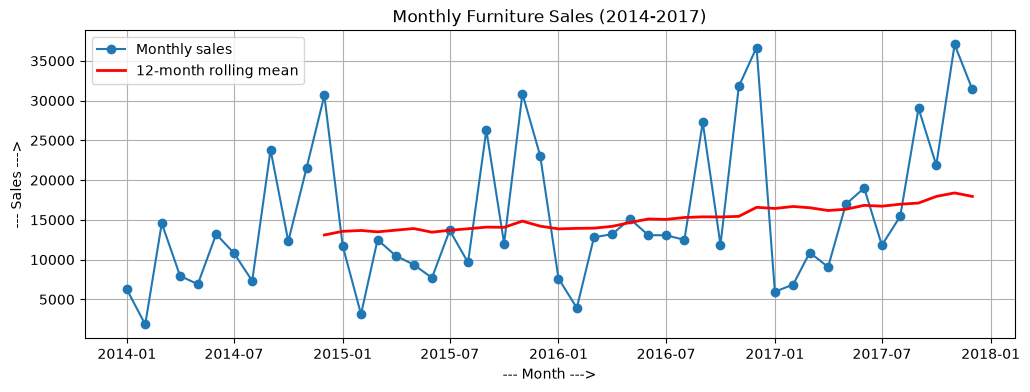

In [6]:
#Trend analysis and highlighting seasonality
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, marker='o', label='Monthly sales')
plt.plot(monthly.index, monthly.rolling(12).mean(), color='red', linewidth=2, label='12-month rolling mean')
plt.xlabel('--- Month --->')
plt.ylabel('--- Sales --->')
plt.title('Monthly Furniture Sales (2014-2017)')
plt.legend()
plt.grid()
plt.show()

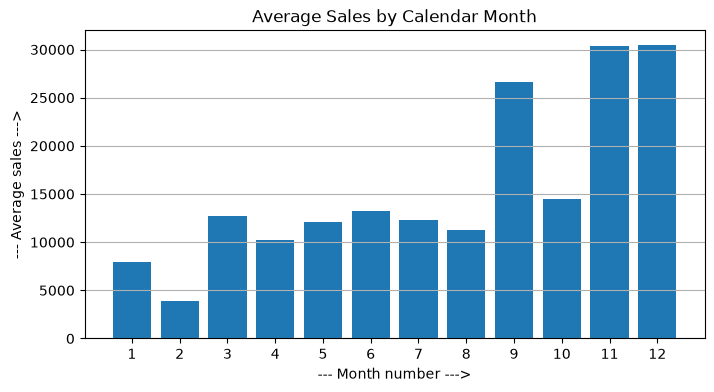

In [7]:
# average monthly sales 
month_avg = monthly.groupby(monthly.index.month).mean()

plt.figure(figsize=(8, 4))
plt.bar(month_avg.index, month_avg.values)
plt.xticks(range(1, 13))
plt.xlabel('--- Month number --->')
plt.ylabel('--- Average sales --->')
plt.title('Average Sales by Calendar Month')
plt.grid(axis='y')
plt.show()

In [8]:
# yearly trend/growth 
yearly = monthly.groupby(monthly.index.year).sum()
print(yearly.round(0))
print()
print('Year-on-year growth (%):')
print((yearly.pct_change() * 100).round(1))

Order Date
2014    157193.0
2015    170518.0
2016    198901.0
2017    215387.0
Name: Sales, dtype: float64

Year-on-year growth (%):
Order Date
2014     NaN
2015     8.5
2016    16.6
2017     8.3
Name: Sales, dtype: float64


In [9]:
#Train on data before 2017
train = monthly[:'2016-12-01']

In [10]:
#Test on data of the year 2017
test = monthly['2017-01-01':]

In [11]:
#train.head()
#test.head()
print('Train months =', len(train), '|', train.index.min().date(), 'to', train.index.max().date())
print('Test months  =', len(test), '|', test.index.min().date(), 'to', test.index.max().date())

Train months = 36 | 2014-01-01 to 2016-12-01
Test months  = 12 | 2017-01-01 to 2017-12-01


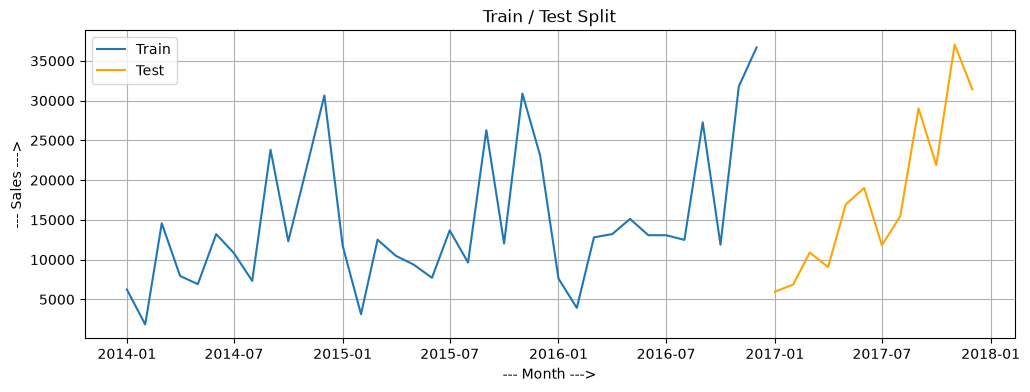

In [12]:
#Training and testing size in chart
plt.figure(figsize=(12, 4))
plt.plot(train.index, train.values, label='Train')
plt.plot(test.index, test.values, label='Test', color='orange')
plt.xlabel('--- Month --->')
plt.ylabel('--- Sales --->')
plt.title('Train / Test Split')
plt.legend()
plt.grid()
plt.show()

In [13]:
#Time index (trend) + month dummies (seasonality) for the given dates
#Method to combine trend and seanonality values
def make_features(index, start_date):
    t = ((index.year - start_date.year) * 12 + (index.month - start_date.month)).values
    X = pd.DataFrame({'t': t}, index=index)
    for m in range(2, 13):
        X['m' + str(m)] = (index.month == m).astype(int)
    return X


In [14]:
start = monthly.index.min()

X_train = make_features(train.index, start)
X_test = make_features(test.index, start)

lr = LinearRegression()
lr.fit(X_train, train.values)

pred_lr = pd.Series(lr.predict(X_test), index=test.index)
print('Trend coefficient (sales added per month) =', round(lr.coef_[0], 2))
pred_lr.round(0)

Trend coefficient (sales added per month) = 144.82


Order Date
2017-01-01    12011.0
2017-02-01     6442.0
2017-03-01    16767.0
2017-04-01    14020.0
2017-05-01    13945.0
2017-06-01    14806.0
2017-07-01    15997.0
2017-08-01    13290.0
2017-09-01    29260.0
2017-10-01    15544.0
2017-11-01    31552.0
2017-12-01    33613.0
Freq: MS, dtype: float64

In [15]:
#Evaluation Method
def evaluate(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    return mae, rmse, mape

In [17]:
pred_naive = pd.Series(train[-12:].values, index=test.index)
pred_naive

Order Date
2017-01-01     7622.7430
2017-02-01     3925.5510
2017-03-01    12801.0920
2017-04-01    13212.0900
2017-05-01    15119.8350
2017-06-01    13070.5720
2017-07-01    13068.5190
2017-08-01    12483.2323
2017-09-01    27262.8809
2017-10-01    11872.5770
2017-11-01    31783.6288
2017-12-01    36678.7150
Freq: MS, dtype: float64

In [21]:
predictions = {'Seasonal Naive': pred_naive,
               'Linear Regression': pred_lr}
               

results = pd.DataFrame(
    {name: evaluate(test, p) for name, p in predictions.items()},
    index=['MAE', 'RMSE', 'MAPE (%)']).T.round(2)

results = results.sort_values('RMSE')
results

,MAE,RMSE,MAPE (%)
Linear Regression,3760.99,4282.53,29.75
Seasonal Naive,3747.03,4473.38,24.05


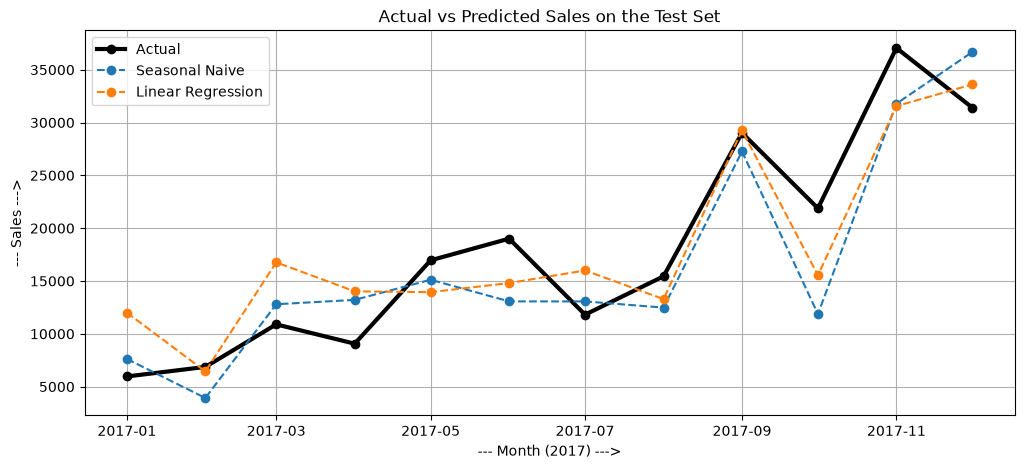

Best model (lowest RMSE) = Linear Regression


In [23]:
#Chart Representation of the differences between Seasonal Naive, Linear Regression and Actual values 
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, marker='o', linewidth=3, color='black', label='Actual')
for name, p in predictions.items():
    plt.plot(p.index, p.values, marker='o', linestyle='--', label=name)
plt.xlabel('--- Month (2017) --->')
plt.ylabel('--- Sales --->')
plt.title('Actual vs Predicted Sales on the Test Set')
plt.legend()
plt.grid()
plt.show()

best_model = results.index[0]
print('Best model (lowest RMSE) =', best_model)

In [24]:
#The Best model is now trained on all 48 months
horizon = 12
future_index = pd.date_range(monthly.index.max() + pd.offsets.MonthBegin(1), periods=horizon, freq='MS')

if best_model == 'Linear Regression':
    lr_final = LinearRegression().fit(make_features(monthly.index, start), monthly.values)
    forecast = pd.Series(lr_final.predict(make_features(future_index, start)), index=future_index)

else:   # Seasonal Naive
    forecast = pd.Series(monthly[-12:].values, index=future_index)


In [25]:
#Then it is used to forecast the next 12 months (Year 2018)
forecast = forecast.clip(lower=0)      # sales cannot be negative
print('Final model used:', best_model)
forecast.round(0)

Final model used: Linear Regression


2018-01-01    12121.0
2018-02-01     8170.0
2018-03-01    16921.0
2018-04-01    14403.0
2018-05-01    16320.0
2018-06-01    17478.0
2018-07-01    16573.0
2018-08-01    15449.0
2018-09-01    30824.0
2018-10-01    18750.0
2018-11-01    34550.0
2018-12-01    34683.0
Freq: MS, dtype: float64

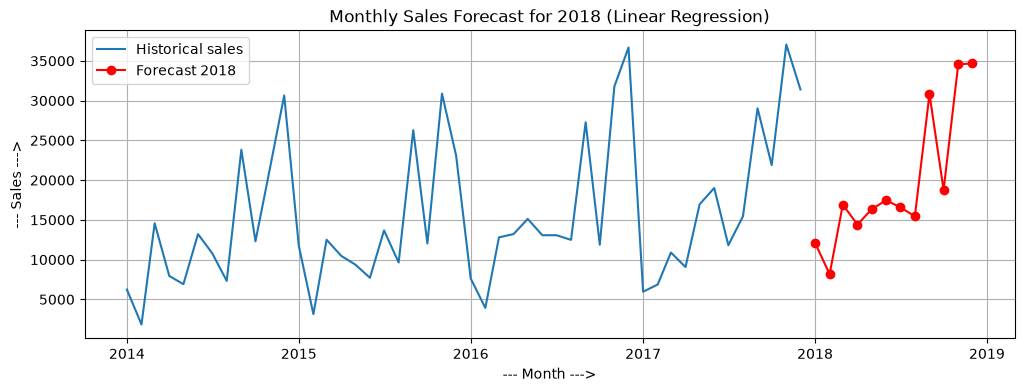

Forecast total sales for 2018 = 236242.0
Actual total sales for 2017   = 215387.0
Peak forecast month           = December 2018


In [26]:
#Chart 
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, label='Historical sales')
plt.plot(forecast.index, forecast.values, color='red', marker='o', label='Forecast 2018')
plt.xlabel('--- Month --->')
plt.ylabel('--- Sales --->')
plt.title('Monthly Sales Forecast for 2018 (' + best_model + ')')
plt.legend()
plt.grid()
plt.show()

print('Forecast total sales for 2018 =', round(forecast.sum(), 0))
print('Actual total sales for 2017   =', round(monthly['2017'].sum(), 0))
print('Peak forecast month           =', forecast.idxmax().strftime('%B %Y'))